# Quem era de esquerda e virou direita? Votos por cargo, 2002–2026

Análise com dados públicos do TSE (votos por candidato, município e zona, 2002–2026) e do IBGE (Censo 2022).
Pergunta: municípios e estados que votavam majoritariamente à esquerda por muito tempo passaram a votar na direita? Em que eleição, em que cargos e com que perfil?

**Leitura obrigatória antes dos números:**
- A unidade de análise é o **município**. Perfil de município (renda, religião, idade) **não é** perfil de eleitor: "cidades mais evangélicas viraram mais" não significa "evangélicos viraram".
- Esquerda / centro / direita é uma **classificação de partidos feita por mim** (tabela em `src/partido_ideologia.py`). É um julgamento; testo uma classificação alternativa.
- Só votos **nominais** (candidatos). Votos de legenda em eleições proporcionais ficam de fora.
- 2026 é só o 1º turno (4/10/2026). O exterior e o voto em trânsito ficam de fora das análises municipais.

## Resumo

**1. A virada é real, mas aconteceu em 2018 e 2026 só a ampliou.** Dos 4.100 municípios que deram mais de 50% à esquerda em pelo menos 3 das 4 eleições presidenciais de 2002 a 2014 (83% dos votos de 2022), **1.608 (39%) têm a direita à frente em 2026**, que somam 51% dos votos de 2022 desse grupo. Quase todos (1.238 de 1.288) já tinham virado em 2018; 42 viraram em 2022 e **328 viraram só agora** (municípios pequenos: 2,3 milhões de votos, contra 46,8 milhões dos que viraram em 2018). 50 que viraram em 2018 voltaram à esquerda.

**2. Estados.** Com a direita à frente em 2026 e esquerda maioria em 2002–2014: RJ, ES, DF, GO, MT, MS, PR, RS, SC, SP, MG, RO, AC, RR e, só em 2026, TO e AP. No Nordeste e no Pará a esquerda segue à frente. O Amazonas ficou em 48,4% para a esquerda contra 46,8% para a direita.

**3. Não é só o presidente.** Nos municípios que viraram, a esquerda perdeu 27 p.p. no voto presidencial (média 2002–14 → 2026), mas só 9–10 p.p. para deputado e senador. Nos que ficaram, a esquerda *subiu* 4,4 p.p. para senador. A direita lidera o governo estadual em 78% dos votos dos municípios que viraram, contra 39% nos que ficaram.

**4. Perfil (do município, não do eleitor).** Os que viraram são mais urbanos (94% × 80%), mais ricos (renda média de R$ 2.193 × R$ 1.659), com mais evangélicos (30,5% × 23,0%) e menos pretos e pardos (52,5% × 66,3%) que os que ficaram. Parte disso é região. Dentro do mesmo estado, +1 desvio-padrão de evangélicos acompanha +8,4 p.p. de direita e +1 DP de pretos e pardos acompanha −7,5 p.p. Perfil e UF juntos explicam 84% da variação, e só o perfil explica 74%.

**5. 2026 em si.** A mudança 2022→2026 tem outro padrão: evangélicos deixam de pesar (efeito próximo de zero) e os demais coeficientes ficam em torno de 1 p.p. por desvio-padrão. A grande divisão por religião e cor/raça foi feita em 2018.

**6. Políticos.** Candidatos a deputado federal por partidos de direita com título de segurança/militar no nome de urna (delegado, sargento, coronel...) passaram de 1,1% dos votos do bloco em 2002 para 9,4% em 2026 (7,8% já em 2018). Títulos religiosos caíram de 4,6% para 0,9%.

**Cuidado com a leitura:** os resultados dependem da classificação dos partidos (PSDB e MDB como centro). Contando o centro como direita, 64% dos votos dos municípios históricos já não dão maioria à esquerda em 2026 (contra 51% na definição principal).

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.formula.api as smf

pd.set_option("display.width", 160, "display.max_columns", 30, "display.float_format", "{:.1f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COR = {"esquerda": "#c0392b", "centro": "#95a5a6", "direita": "#1f4e9c"}
P = "../data/processed/"

## 1. Dados e classificação dos partidos

Cada partido é esquerda, centro ou direita (tabela abaixo). Mudanças de sigla (PMDB→MDB, PFL→DEM→UNIÃO, PPB→PP, PR→PL, PSL→UNIÃO etc.) contam como o mesmo partido.
O ponto mais sensível: o **PSDB e o MDB estão no centro**. Por isso, até 2014 a "direita" quase não aparece na eleição presidencial (o adversário do PT era o PSDB). Na seção 7 refaço tudo tratando o centro como direita.

In [ ]:
ide = pd.read_csv(P + "partido_ideologia.csv")
for k, g in ide.groupby("ideologia"):
    print(f"{k.upper():9s}", ", ".join(g.SG_PARTIDO))

mun = pd.read_parquet(P + "municipios_tse.parquet")      # 5.571 municípios (sem exterior/trânsito)
uf = mun.set_index("CD_MUNICIPIO").SG_UF
v = pd.read_parquet(P + "votos_partido_municipio.parquet")
v = v[(v.NR_TURNO == 1) & v.CD_MUNICIPIO.isin(mun.CD_MUNICIPIO)].merge(ide, on="SG_PARTIDO", how="left")
assert v.ideologia.notna().all()

# votos por (cargo, ano, município, ideologia)
vot = (v.pivot_table(index=["cargo", "ano", "CD_MUNICIPIO"], columns="ideologia",
                     values="QT_VOTOS_NOMINAIS", aggfunc="sum", fill_value=0))
vot["tot"] = vot.sum(axis=1)
sh = vot[["esquerda", "centro", "direita"]].div(vot.tot, axis=0)
sh["tot"] = vot.tot
sh["uf"] = sh.index.get_level_values("CD_MUNICIPIO").map(uf)
print("\nlinhas município x ano x cargo:", len(sh))

CENTRO    PSDB, PMDB, MDB, PSD, PODE, PTN, SOLIDARIEDADE, SD, AVANTE, PT do B, PROS, PMN, MOBILIZA, PPS, CIDADANIA, PHS, PAN, PGT, DEMOCRATA
DIREITA   PL, PR, PSL, PP, PPB, PFL, DEM, UNIÃO, REPUBLICANOS, PRB, PSC, PTB, NOVO, PRTB, PRP, PTC, PSDC, DC, PATRIOTA, PATRI, PEN, PRONA, PST, AGIR, PMB, PRD, MISSÃO
ESQUERDA  PT, PSB, PDT, PSOL, PC do B, PCDOB, PCB, PSTU, PCO, UP, REDE, PPL, PV



linhas município x ano x cargo: 194885


**Checagem**: o 1º turno presidencial de 2022 e o de 2026 batem com o notebook anterior (diferença pequena em 2026 porque aqui o exterior fica de fora).

In [ ]:
chk = (v[v.cargo == "presidente"].groupby(["ano", "SG_PARTIDO"]).QT_VOTOS_NOMINAIS.sum()
       .groupby("ano").apply(lambda s: (100 * s / s.sum()).sort_values(ascending=False).head(3).round(1)))
print(chk.droplevel(0).loc[[2022, 2026]].to_string())

ano   SG_PARTIDO
2022  PT           48.4
      PL           43.2
      MDB           4.2
2026  PL           47.0
      PT           45.2
      AVANTE        2.9


## 2. Série nacional por cargo

Participação de cada bloco nos votos nominais, 1º turno. Mostra se a mudança é só presidencial ou aparece em todos os cargos.

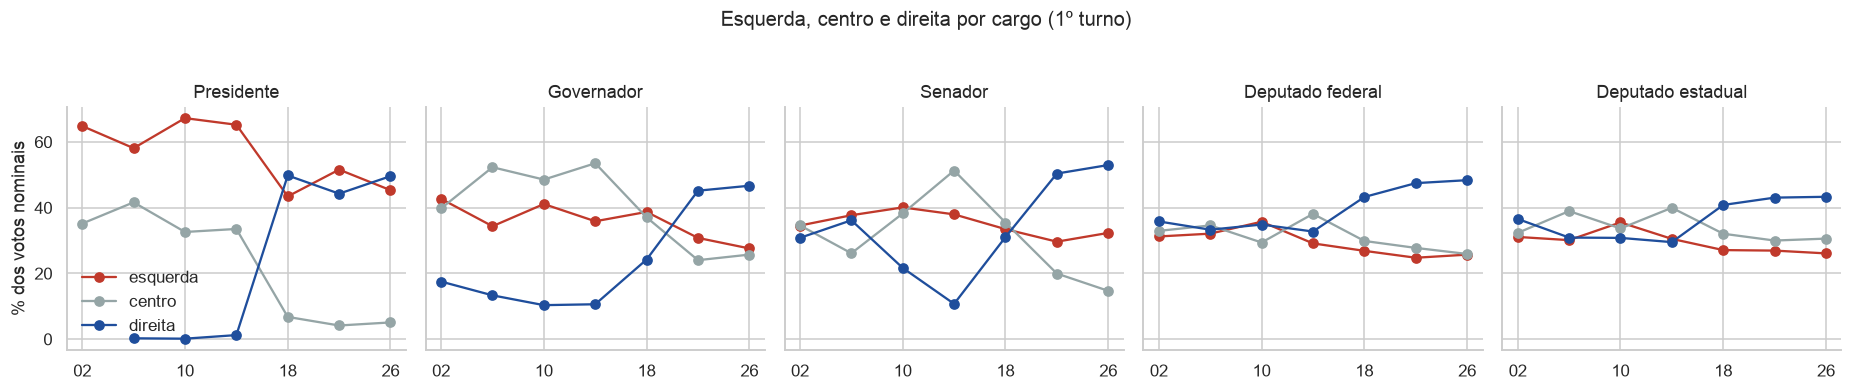


Direita (% dos votos nominais)
ano           2002  2006  2010  2014  2018  2022  2026
cargo                                                 
presidente     0.0   0.3   0.1   1.2  49.8  44.3  49.6
governador    17.5  13.3  10.3  10.6  24.2  45.2  46.7
senador       30.8  36.2  21.7  10.7  31.1  50.4  53.0
dep_federal   35.8  33.3  34.9  32.7  43.3  47.5  48.4
dep_estadual  36.6  30.9  30.8  29.5  40.8  43.1  43.3

Esquerda (% dos votos nominais)
ano           2002  2006  2010  2014  2018  2022  2026
cargo                                                 
presidente    64.8  58.1  67.2  65.2  43.4  51.6  45.3
governador    42.7  34.4  41.1  35.9  38.7  30.8  27.6
senador       34.6  37.7  40.1  38.0  33.5  29.7  32.3
dep_federal   31.2  32.1  35.7  29.1  26.9  24.8  25.7
dep_estadual  31.1  30.1  35.5  30.5  27.1  26.9  26.1


In [ ]:
nat = (v.groupby(["cargo", "ano", "ideologia"]).QT_VOTOS_NOMINAIS.sum().unstack("ideologia"))
nat = 100 * nat.div(nat.sum(axis=1), axis=0)
ordem = ["presidente", "governador", "senador", "dep_federal", "dep_estadual"]
nomes = {"presidente": "Presidente", "governador": "Governador", "senador": "Senador",
         "dep_federal": "Deputado federal", "dep_estadual": "Deputado estadual"}
fig, axs = plt.subplots(1, 5, figsize=(17, 3.4), sharey=True)
for ax, c in zip(axs, ordem):
    d = nat.loc[c]
    for k in ["esquerda", "centro", "direita"]:
        ax.plot(d.index, d[k], marker="o", color=COR[k], label=k)
    ax.set_title(nomes[c]); ax.set_xticks([2002, 2010, 2018, 2026]); ax.set_xticklabels(["02", "10", "18", "26"])
axs[0].set_ylabel("% dos votos nominais"); axs[0].legend(frameon=False)
fig.suptitle("Esquerda, centro e direita por cargo (1º turno)", y=1.04, fontsize=13)
plt.tight_layout(); plt.show()
print(nat.round(1).unstack("ano").to_string() if False else "")
tab = nat.reset_index().pivot(index="cargo", columns="ano", values="direita").loc[ordem]
print("Direita (% dos votos nominais)"); print(tab.fillna(0).round(1).to_string())
tab = nat.reset_index().pivot(index="cargo", columns="ano", values="esquerda").loc[ordem]
print("\nEsquerda (% dos votos nominais)"); print(tab.round(1).to_string())

## 3. Estados: quem tinha esquerda forte até 2014 e onde a direita passou

Para cada UF, % de voto em partidos de esquerda no 1º turno presidencial.

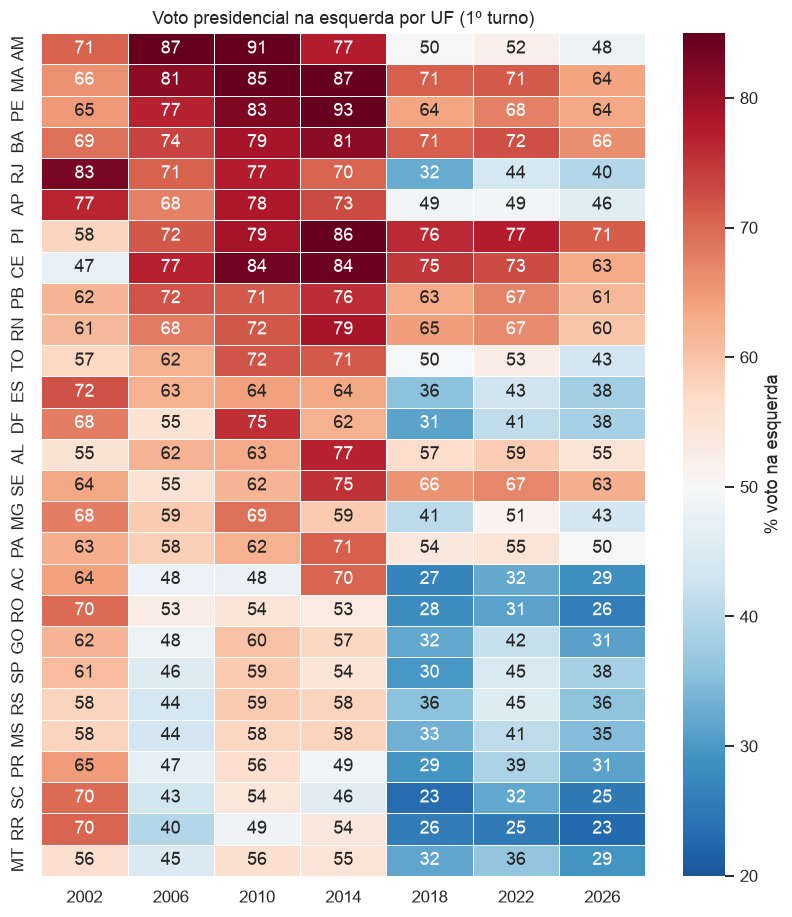

In [ ]:
pres = sh.loc["presidente"]
E = pres.esquerda.unstack("ano"); D = pres.direita.unstack("ano"); Cn = pres.centro.unstack("ano")
T = pres.tot.unstack("ano")
ufs = pres.uf.groupby("CD_MUNICIPIO").first()

def uf_share(col):
    out = {}
    for y in E.columns:
        s = (pres[col].xs(y, level="ano") * pres.tot.xs(y, level="ano")).groupby(ufs).sum()
        out[y] = 100 * s / pres.tot.xs(y, level="ano").groupby(ufs).sum()
    return pd.DataFrame(out)
UE, UD = uf_share("esquerda"), uf_share("direita")
ord_uf = UE[[2002, 2006, 2010, 2014]].mean(axis=1).sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(7.5, 8.5))
sns.heatmap(UE.loc[ord_uf], annot=True, fmt=".0f", cmap="RdBu_r", center=50, vmin=20, vmax=85,
            cbar_kws={"label": "% voto na esquerda"}, linewidths=.4, ax=ax)
ax.set_title("Voto presidencial na esquerda por UF (1º turno)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [ ]:
res = pd.DataFrame({
    "esq 2002-14 (média)": UE[[2002, 2006, 2010, 2014]].mean(axis=1),
    "esq 2018": UE[2018], "esq 2022": UE[2022], "esq 2026": UE[2026],
    "dir 2022": UD[2022], "dir 2026": UD[2026],
})
res["Δ esq 2002-14 → 2026 (p.p.)"] = res["esq 2026"] - res["esq 2002-14 (média)"]
res["direita à frente em 2026"] = res["dir 2026"] > res["esq 2026"]
def prim(u):
    for y in (2018, 2022, 2026):
        if UD.loc[u, y] > UE.loc[u, y]:
            return str(y)
    return "nunca"
res["1ª vez com direita à frente"] = [prim(u) for u in res.index]
print(res.sort_values("Δ esq 2002-14 → 2026 (p.p.)").round(1).to_string())

    esq 2002-14 (média)  esq 2018  esq 2022  esq 2026  dir 2022  dir 2026  Δ esq 2002-14 → 2026 (p.p.)  direita à frente em 2026 1ª vez com direita à frente
uf                                                                                                                                                          
RJ                 75.4      32.2      44.0      39.7      52.1      55.5                        -35.7                      True                        2018
AM                 81.7      50.0      51.8      48.4      44.0      46.8                        -33.3                     False                       nunca
RO                 57.5      27.9      31.2      26.0      65.4      69.6                        -31.5                      True                        2018
RR                 53.2      25.7      25.4      23.0      70.3      73.2                        -30.2                      True                        2018
AC                 57.6      26.6      32.1      28.9     

## 4. Municípios: definição de "esquerda histórica" e de "virada"

- **Esquerda histórica**: esquerda com mais de 50% dos votos presidenciais em pelo menos 3 dos 4 primeiros 1º turnos (2002, 2006, 2010, 2014), antes do ciclo Bolsonaro. Defino a história sem olhar 2018–2026 para não escolher o grupo pelo resultado.
- **Virou**: em 2026 a direita tem mais votos que a esquerda no município (hoje isso é, na prática, Flávio à frente de Lula).
- **Quando**: primeira eleição (2018, 2022 ou 2026) em que a direita passou a esquerda no município.

In [ ]:
hist_n = (E[[2002, 2006, 2010, 2014]] > .5).sum(axis=1)
hist = hist_n >= 3
virou26 = D[2026] > E[2026]
peso = T[2022]

def flip_year(r):
    for y in (2018, 2022, 2026):
        if r[("d", y)] > r[("e", y)]:
            return str(y)
    return "nunca"
fy = pd.concat({"e": E[[2018, 2022, 2026]], "d": D[[2018, 2022, 2026]]}, axis=1).apply(flip_year, axis=1)

base = pd.DataFrame({"uf": ufs, "historica": hist, "virou26": virou26, "primeira_virada": fy, "peso": peso})
base = base.dropna(subset=["peso"])
print(f"Municípios com esquerda histórica: {int(base.historica.sum())} de {len(base)} ({100*base.peso[base.historica].sum()/base.peso.sum():.0f}% dos votos de 2022)")
h = base[base.historica]
print(f"Desses, com a direita à frente em 2026: {int(h.virou26.sum())} ({100*h.virou26.mean():.0f}% dos municípios, {100*h.peso[h.virou26].sum()/h.peso.sum():.0f}% dos votos)")

def tabela(df, by):
    t = df.groupby(by).apply(lambda g: pd.Series({
        "municípios": int(len(g)), "virou_2026": int(g.virou26.sum()),
        "% municípios": 100 * g.virou26.mean(),
        "votos 2022 dos que viraram (mi)": g.peso[g.virou26].sum() / 1e6}))
    return t.astype({"municípios": int, "virou_2026": int})
print()
print(tabela(h, "primeira_virada").round(1).to_string())
print("\n2018 → 2026: dos municípios que viraram já em 2018, %d voltaram a ter esquerda à frente em 2026." %
      int(((h.primeira_virada == "2018") & ~h.virou26).sum()))

Municípios com esquerda histórica: 4100 de 5570 (83% dos votos de 2022)
Desses, com a direita à frente em 2026: 1608 (39% dos municípios, 51% dos votos)

                 municípios  virou_2026  % municípios  votos 2022 dos que viraram (mi)
primeira_virada                                                                       
2018                   1288        1238          96.1                             46.8
2022                     42          42         100.0                              0.3
2026                    328         328         100.0                              2.3
nunca                  2442           0           0.0                              0.0

2018 → 2026: dos municípios que viraram já em 2018, 50 voltaram a ter esquerda à frente em 2026.


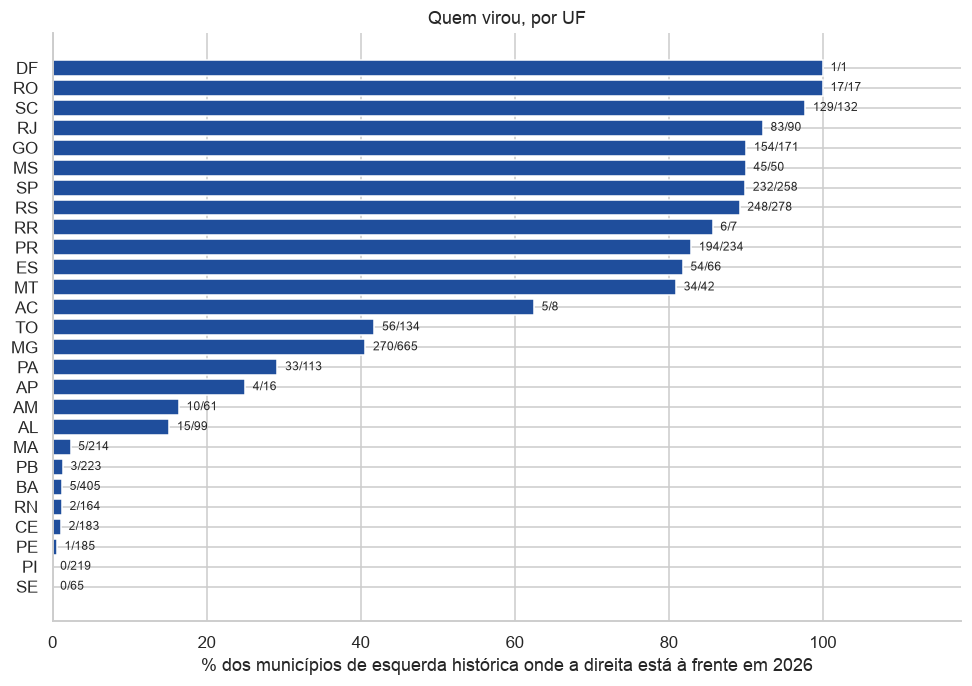

In [ ]:
t = tabela(h, "uf").sort_values("% municípios", ascending=False)
fig, ax = plt.subplots(figsize=(9, 6.4))
ax.barh(t.index[::-1], t["% municípios"][::-1], color="#1f4e9c")
for i, (u, r) in enumerate(t[::-1].iterrows()):
    ax.text(r["% municípios"] + 1, i, f"{int(r.virou_2026)}/{int(r['municípios'])}", va="center", fontsize=8)
ax.set_xlim(0, 118); ax.set_xlabel("% dos municípios de esquerda histórica onde a direita está à frente em 2026")
ax.set_title("Quem virou, por UF"); plt.tight_layout(); plt.show()

### Quando virou?

Evolução do conjunto de municípios de esquerda histórica: em cada eleição, qual fração tem a direita à frente (ponderado pelos votos).

      % votos na esquerda  % votos no centro  % votos na direita  % municípios com direita à frente
ano                                                                                                
2002                 66.5               33.5                 0.0                                0.0
2006                 62.4               37.4                 0.3                                0.0
2010                 70.9               28.9                 0.1                                0.0
2014                 69.5               29.3                 1.3                                0.0
2018                 47.4                6.0                46.6                               31.4
2022                 55.0                4.0                40.9                               22.2
2026                 48.9                5.0                46.1                               39.2


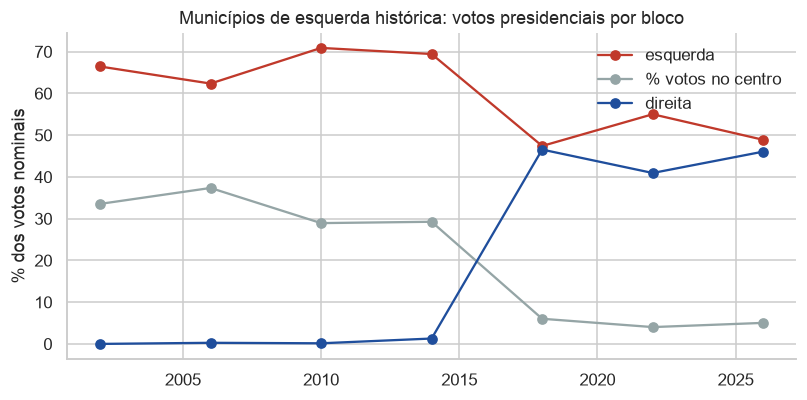

In [ ]:
rows = []
for y in (2002, 2006, 2010, 2014, 2018, 2022, 2026):
    m = base.index[base.historica]
    w = T[y].reindex(m)
    rows.append({"ano": y, "% votos na esquerda": 100 * (E[y].reindex(m) * w).sum() / w.sum(),
                 "% votos no centro": 100 * (Cn[y].reindex(m) * w).sum() / w.sum(),
                 "% votos na direita": 100 * (D[y].reindex(m) * w).sum() / w.sum(),
                 "% municípios com direita à frente": 100 * (D[y].reindex(m) > E[y].reindex(m)).mean()})
ev = pd.DataFrame(rows).set_index("ano")
print(ev.round(1).to_string())
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for k, c in [("% votos na esquerda", COR["esquerda"]), ("% votos no centro", COR["centro"]), ("% votos na direita", COR["direita"])]:
    ax.plot(ev.index, ev[k], marker="o", color=c, label=k.replace("% votos na ", ""))
ax.set_title("Municípios de esquerda histórica: votos presidenciais por bloco"); ax.legend(frameon=False)
ax.set_ylabel("% dos votos nominais"); plt.tight_layout(); plt.show()

## 5. Só o presidente? A virada em outros cargos

Para os mesmos municípios, mudança na participação da esquerda (em pontos percentuais) entre a **média 2002–2014** e **2026**, por cargo. Separo os municípios de esquerda histórica que viraram no voto presidencial dos que não viraram.

In [ ]:
base["grupo"] = np.where(~base.historica, "não era esquerda histórica",
                np.where(base.virou26, "esquerda histórica — virou", "esquerda histórica — ficou"))
def media_w(cargo, anos, col):
    x = sh.loc[cargo]
    d = x[x.index.get_level_values("ano").isin(anos)]
    return (d[col] * d.tot).groupby("CD_MUNICIPIO").sum() / d.tot.groupby("CD_MUNICIPIO").sum()

linhas = []
for c in ordem:
    e0 = media_w(c, [2002, 2006, 2010, 2014], "esquerda"); e1 = media_w(c, [2026], "esquerda")
    d0 = media_w(c, [2002, 2006, 2010, 2014], "direita"); d1 = media_w(c, [2026], "direita")
    df = base.join(pd.DataFrame({"de": e1 - e0, "dd": d1 - d0}), how="left")
    for g, x in df.groupby("grupo"):
        linhas.append({"cargo": nomes[c], "grupo": g, "Δ esquerda (p.p.)": 100 * np.average(x.de.fillna(0), weights=x.peso),
                       "Δ direita (p.p.)": 100 * np.average(x.dd.fillna(0), weights=x.peso)})
cg = pd.DataFrame(linhas)
print(cg.pivot(index="cargo", columns="grupo", values="Δ esquerda (p.p.)").loc[[nomes[c] for c in ordem]].round(1).to_string())
print()
print(cg.pivot(index="cargo", columns="grupo", values="Δ direita (p.p.)").loc[[nomes[c] for c in ordem]].round(1).to_string())

grupo              esquerda histórica — ficou  esquerda histórica — virou  não era esquerda histórica
cargo                                                                                                
Presidente                              -10.7                       -27.3                       -19.3
Governador                               -8.1                       -15.0                        -8.1
Senador                                   4.4                        -9.8                       -12.8
Deputado federal                         -2.1                        -8.7                        -9.1
Deputado estadual                         1.5                        -9.9                       -11.5

grupo              esquerda histórica — ficou  esquerda histórica — virou  não era esquerda histórica
cargo                                                                                                
Presidente                               35.1                        56.1        

**Voto dividido em 2026**: nos municípios que viraram para a direita na eleição presidencial, em que cargos a esquerda ainda lidera? (liderança entre os três blocos)

In [ ]:
lid = []
for c in ordem:
    x = sh.loc[c].xs(2026, level="ano")[["esquerda", "centro", "direita"]]
    x = x.assign(lider=x.idxmax(axis=1)).join(base[["grupo", "peso"]], how="inner")
    t = x.pivot_table(index="grupo", columns="lider", values="peso", aggfunc="sum", fill_value=0)
    t = t.reindex(columns=["esquerda", "centro", "direita"], fill_value=0)
    t = 100 * t.div(t.sum(axis=1), axis=0)
    t["cargo"] = nomes[c]; lid.append(t.reset_index())
lid = pd.concat(lid).set_index(["cargo", "grupo"])[["esquerda", "centro", "direita"]]
print("% dos votos (2026) em municípios onde cada bloco lidera o cargo")
print(lid.loc[[nomes[c] for c in ordem]].round(0).to_string())

% dos votos (2026) em municípios onde cada bloco lidera o cargo
lider                                         esquerda  centro  direita
cargo             grupo                                                
Presidente        esquerda histórica — ficou     100.0     0.0      0.0
                  esquerda histórica — virou       0.0     0.0    100.0
                  não era esquerda histórica       3.0     0.0     97.0
Governador        esquerda histórica — ficou      29.0    32.0     39.0
                  esquerda histórica — virou       0.0    21.0     78.0
                  não era esquerda histórica       1.0     7.0     92.0
Senador           esquerda histórica — ficou      44.0    18.0     38.0
                  esquerda histórica — virou       2.0     8.0     90.0
                  não era esquerda histórica       1.0     3.0     96.0
Deputado federal  esquerda histórica — ficou      19.0    25.0     56.0
                  esquerda histórica — virou       2.0    10.0     88.0


## 6. Perfil dos municípios que viraram

Compara os municípios de esquerda histórica que **viraram** com os que **ficaram**, e com o resto. Variáveis do Censo 2022 (renda, urbanização, religião, cor/raça, escolaridade) e do eleitorado de 2026 (idade). Médias ponderadas pelos votos de 2022.

Lembrete: é perfil do município, não do eleitor.

In [ ]:
ib = pd.read_parquet(P + "ibge_perfil_extra.parquet").set_index("CD_MUNICIPIO")
pe = pd.read_parquet(P + "perfil_eleitorado.parquet")
pe = pe[(pe.ano == 2026) & pe.CD_MUNICIPIO.isin(mun.CD_MUNICIPIO) & (pe.faixa != "Inválido")]
tot = pe.groupby("CD_MUNICIPIO").QT_ELEITORES.sum()
idade = pd.DataFrame({
    "pct_16_34": 100 * pe[pe.faixa.isin(["16-17", "18-24"])].groupby("CD_MUNICIPIO").QT_ELEITORES.sum() / tot,
    "pct_60mais": 100 * pe[pe.faixa.isin(["60-69", "70+"])].groupby("CD_MUNICIPIO").QT_ELEITORES.sum() / tot})
# 25-44 inclui parte dos 25-34; por isso 16-34 aqui é só 16-24 (limite da faixa disponível)
idade = idade.rename(columns={"pct_16_34": "pct_16_24"})

perf = base.join(ib.drop(columns=["cd_ibge"]), how="left").join(idade, how="left")
perf["renda"] = perf.renda
perf["pop_mil"] = perf["pop"] / 1000
cols = {"renda": "Renda média (R$)", "pct_urbano": "% urbano", "pct_evang": "% evangélicos", "pct_catolico": "% católicos",
        "pct_sem_religiao": "% sem religião", "pct_preta_parda": "% pretos e pardos", "pct_inst_baixa": "% adultos até fund. incompleto",
        "pct_superior": "% adultos com superior", "pct_16_24": "% eleitores 16–24", "pct_60mais": "% eleitores 60+",
        "pop_mil": "População (mil)"}
def wmean(g, c):
    x = g[[c, "peso"]].dropna(); return np.average(x[c], weights=x.peso)
rows = {}
for nome, g in perf.groupby("grupo"):
    rows[nome] = {lab: wmean(g, c) for c, lab in cols.items()}
rows["Brasil"] = {lab: wmean(perf, c) for c, lab in cols.items()}
pf = pd.DataFrame(rows)[["esquerda histórica — virou", "esquerda histórica — ficou", "não era esquerda histórica", "Brasil"]]
print(pf.round(1).to_string())
print("\nmunicípios por grupo:"); print(perf.grupo.value_counts().to_string())

                                esquerda histórica — virou  esquerda histórica — ficou  não era esquerda histórica  Brasil
Renda média (R$)                                    2193.2                      1658.6                      2243.6  1984.7
% urbano                                              93.7                        80.3                        86.4    87.0
% evangélicos                                         30.5                        23.0                        25.9    26.6
% católicos                                           50.9                        61.5                        61.8    57.1
% sem religião                                        10.4                         9.2                         6.5     9.2
% pretos e pardos                                     52.5                        66.3                        37.4    55.4
% adultos até fund. incompleto                        28.1                        37.2                        32.2    32.5
% adultos com su

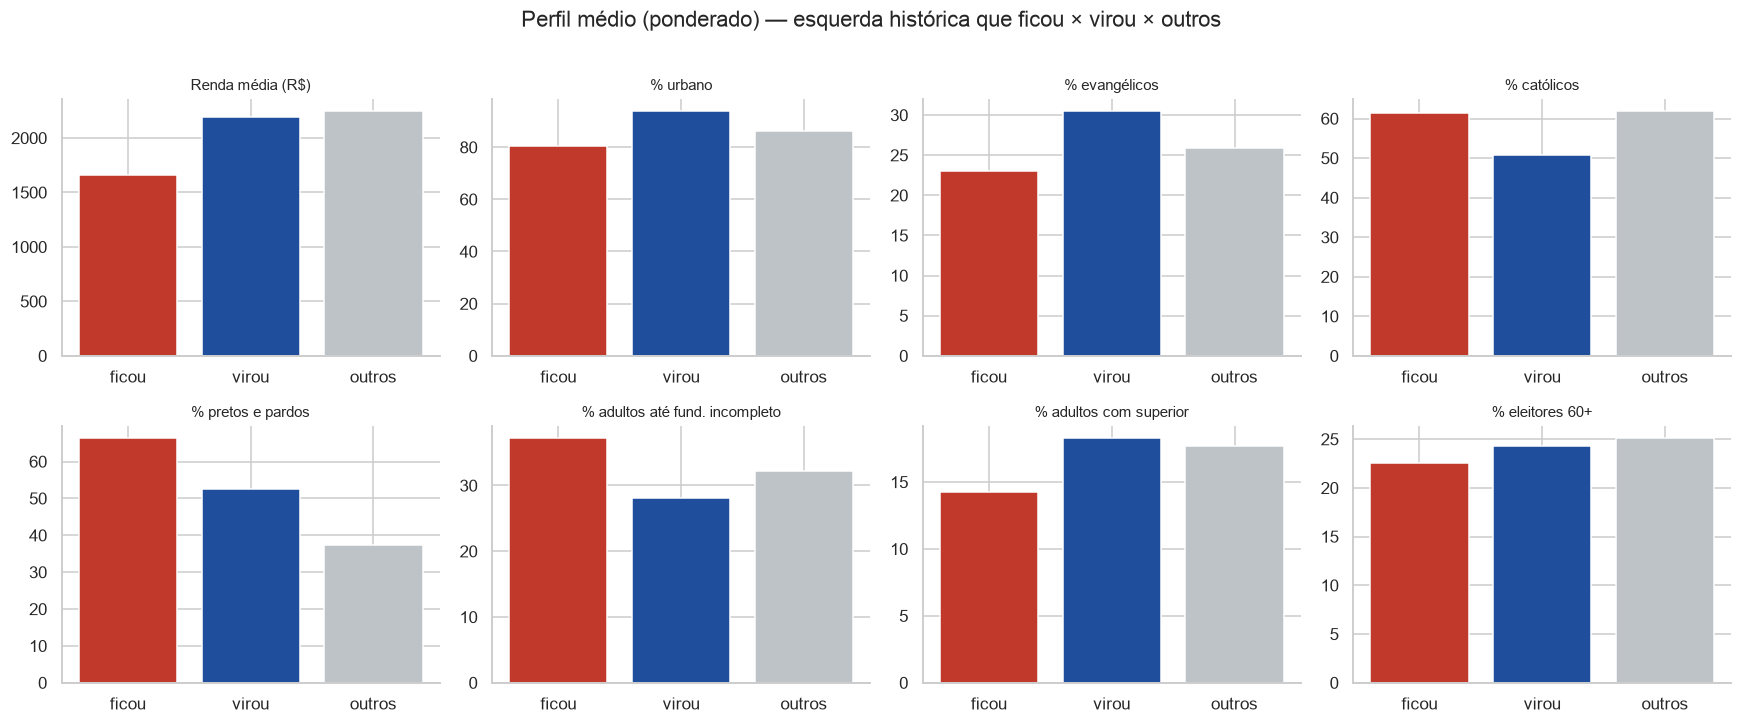

In [ ]:
fig, axs = plt.subplots(2, 4, figsize=(16, 6.5))
ordem_g = ["esquerda histórica — ficou", "esquerda histórica — virou", "não era esquerda histórica"]
cores = ["#c0392b", "#1f4e9c", "#bdc3c7"]
for ax, (c, lab) in zip(axs.ravel(), [(k, v_) for k, v_ in cols.items() if k in
        ("renda", "pct_urbano", "pct_evang", "pct_catolico", "pct_preta_parda", "pct_inst_baixa", "pct_superior", "pct_60mais")]):
    vals = [wmean(perf[perf.grupo == g], c) for g in ordem_g]
    ax.bar(range(3), vals, color=cores); ax.set_xticks(range(3)); ax.set_xticklabels(["ficou", "virou", "outros"])
    ax.set_title(lab, fontsize=10)
fig.suptitle("Perfil médio (ponderado) — esquerda histórica que ficou × virou × outros", y=1.01)
plt.tight_layout(); plt.show()

### Regressão: o que acompanha a virada, dentro do mesmo estado?

Variável explicada: variação da participação da direita no voto presidencial, **média 2002–2014 → 2026** (p.p.), para todos os municípios. Regressão ponderada pelos votos de 2022, erros robustos (HC1). Variáveis padronizadas (coeficiente = efeito de +1 desvio-padrão). Três especificações: só UF; só perfil; perfil + UF.

In [ ]:
d0 = media_w("presidente", [2002, 2006, 2010, 2014], "direita")
reg = perf.join(pd.DataFrame({"dd": 100 * (D[2026] - d0)}), how="left").reset_index().rename(columns={"index": "CD_MUNICIPIO"})
reg["lrenda"] = np.log(reg.renda); reg["lpop"] = np.log(reg["pop"])
xs = ["pct_evang", "pct_catolico", "lrenda", "pct_urbano", "pct_preta_parda", "pct_inst_baixa", "pct_60mais", "pct_16_24", "lpop"]
reg = reg.dropna(subset=["dd", "peso"] + xs)
for x in xs:
    reg[x + "_z"] = (reg[x] - reg[x].mean()) / reg[x].std()
zs = " + ".join(x + "_z" for x in xs)
m_uf = smf.wls("dd ~ C(uf)", reg, weights=reg.peso).fit(cov_type="HC1")
m_pf = smf.wls(f"dd ~ {zs}", reg, weights=reg.peso).fit(cov_type="HC1")
m_all = smf.wls(f"dd ~ {zs} + C(uf)", reg, weights=reg.peso).fit(cov_type="HC1")
print(f"N = {len(reg)} municípios | R² só UF = {m_uf.rsquared:.2f} | só perfil = {m_pf.rsquared:.2f} | perfil + UF = {m_all.rsquared:.2f}")
rotulos = dict(zip([x + "_z" for x in xs], ["% evangélicos", "% católicos", "log renda", "% urbano", "% pretos e pardos",
                "% adultos fund. incompleto", "% eleitores 60+", "% eleitores 16–24", "log população"]))
reg["dd22"] = 100 * (D[2026] - D[2022]).reindex(reg.CD_MUNICIPIO).values
m_22 = smf.wls(f"dd22 ~ {zs} + C(uf)", reg.dropna(subset=["dd22"]), weights=reg.dropna(subset=["dd22"]).peso).fit(cov_type="HC1")
out = pd.DataFrame({"só perfil": m_pf.params, "perfil + UF": m_all.params, "p (perfil+UF)": m_all.pvalues,
                    "Δ2022→26, perfil + UF": m_22.params, "p (Δ2022→26)": m_22.pvalues}).loc[list(rotulos)].rename(index=rotulos)
out["p (perfil+UF)"] = out["p (perfil+UF)"].map(lambda p: "<0,001" if p < .001 else f"{p:.3f}")
out["p (Δ2022→26)"] = out["p (Δ2022→26)"].map(lambda p: "<0,001" if p < .001 else f"{p:.3f}")
print(out.round(2).to_string())
print(f"\nR² do modelo 2022→2026 (perfil + UF): {m_22.rsquared:.2f}")

N = 5567 municípios | R² só UF = 0.64 | só perfil = 0.74 | perfil + UF = 0.84
                            só perfil  perfil + UF p (perfil+UF)  Δ2022→26, perfil + UF p (Δ2022→26)
% evangélicos                    10.6          8.4        <0,001                   -0.4        0.008
% católicos                       3.6          4.9        <0,001                    0.1        0.426
log renda                         7.4          4.3        <0,001                    1.2       <0,001
% urbano                          2.8          3.8        <0,001                    0.3       <0,001
% pretos e pardos                -6.6         -7.5        <0,001                    0.2        0.070
% adultos fund. incompleto        1.4          1.9        <0,001                    1.3       <0,001
% eleitores 60+                  -1.2         -4.3        <0,001                   -0.9       <0,001
% eleitores 16–24                -0.7         -4.9        <0,001                    0.1        0.445
log população

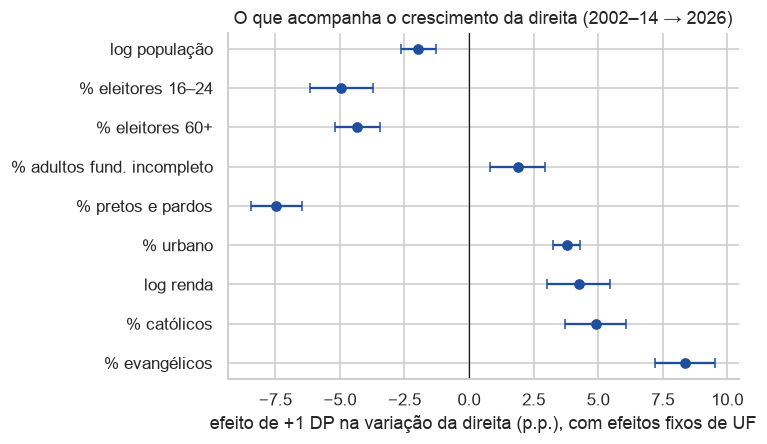

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.2))
y = np.arange(len(rotulos))
ci = m_all.conf_int().loc[list(rotulos)]
ax.errorbar(m_all.params[list(rotulos)], y, xerr=[m_all.params[list(rotulos)] - ci[0], ci[1] - m_all.params[list(rotulos)]],
            fmt="o", color="#1f4e9c", capsize=3)
ax.axvline(0, color="k", lw=.8); ax.set_yticks(y); ax.set_yticklabels(list(rotulos.values()))
ax.set_xlabel("efeito de +1 DP na variação da direita (p.p.), com efeitos fixos de UF")
ax.set_title("O que acompanha o crescimento da direita (2002–14 → 2026)"); plt.tight_layout(); plt.show()

Mesma ideia, restrita aos municípios de **esquerda histórica**, explicando a probabilidade de terem virado (modelo de probabilidade linear ponderado, efeitos fixos de UF):

In [ ]:
rh = reg[reg.historica].copy()
rh["virou"] = rh.virou26.astype(int)
m_h = smf.wls(f"virou ~ {zs} + C(uf)", rh, weights=rh.peso).fit(cov_type="HC1")
print(f"N = {len(rh)} | R² = {m_h.rsquared:.2f}")
tb = pd.DataFrame({"efeito (p.p. de prob.)": 100 * m_h.params, "p": m_h.pvalues}).loc[list(rotulos)].rename(index=rotulos)
tb["p"] = tb["p"].map(lambda p: "<0,001" if p < .001 else f"{p:.3f}")
print(tb.round(1).to_string())

N = 4097 | R² = 0.64
                            efeito (p.p. de prob.)       p
% evangélicos                                 23.2  <0,001
% católicos                                   13.7  <0,001
log renda                                      3.5   0.461
% urbano                                       5.5   0.004
% pretos e pardos                            -19.5  <0,001
% adultos fund. incompleto                    -8.6   0.133
% eleitores 60+                               -9.9   0.009
% eleitores 16–24                             -4.6   0.333
log população                                 -8.9   0.032


## 7. Sensibilidade: e se o centro for contado como direita?

Refaz a contagem de "esquerda histórica que virou" com **direita ampliada** = direita + centro (PSDB, MDB, PSD etc.) e esquerda = esquerda. Aqui "virou" significa que a esquerda deixou de ser maioria do voto presidencial entre os municípios que eram esquerda histórica.

In [ ]:
Ee = E; De = D + Cn
hist_a = (Ee[[2002, 2006, 2010, 2014]] > .5).sum(axis=1) >= 3        # mesma definição de histórico
rows = []
for y in (2018, 2022, 2026):
    nao_maioria = (Ee[y] <= .5)
    rows.append({"ano": y, "% dos municípios históricos sem maioria de esquerda": 100 * nao_maioria[hist_a].mean(),
                 "% dos votos": 100 * T[2022][hist_a & nao_maioria].sum() / T[2022][hist_a].sum()})
print(pd.DataFrame(rows).set_index("ano").round(1).to_string())
print()
chk = pd.DataFrame({"principal (direita à frente)": virou26[hist], "ampliada (esq. perde maioria em 2026)": (Ee[2026] <= .5)[hist_a]})
print("Municípios históricos com direita à frente em 2026 (definição principal):", int(virou26[hist].sum()))
print("Municípios históricos em que a esquerda não tem mais maioria em 2026 (ampliada):", int((Ee[2026] <= .5)[hist].sum()))
print("  dos quais já estavam na definição principal:", int((virou26[hist] & (Ee[2026] <= .5)[hist]).sum()))

      % dos municípios históricos sem maioria de esquerda  % dos votos
ano                                                                   
2018                                                 36.6         63.7
2022                                                 25.8         44.3
2026                                                 42.9         64.0

Municípios históricos com direita à frente em 2026 (definição principal): 1608
Municípios históricos em que a esquerda não tem mais maioria em 2026 (ampliada): 1760
  dos quais já estavam na definição principal: 1608


## 8. Perfil dos políticos: quem cresceu na direita

Votos para deputado federal (1º turno, nacional) por tipo de candidato, separando partidos de direita e de esquerda. Uso o **título no nome de urna** (delegado, sargento, coronel, pastor, bispo etc.), que é o que o eleitor vê na urna.
Não uso a ocupação declarada no registro: a lista de ocupações do TSE mudou em 2010 e as séries não são comparáveis entre os anos.
Limite: título de urna é uma pista, não uma medida completa (muitos candidatos de perfil policial ou religioso não usam título).

votos para deputado federal (milhões):
ano
2002    78.8
2006    84.6
2010    89.4
2014    89.1
2018    91.4
2022   106.0
2026   110.6


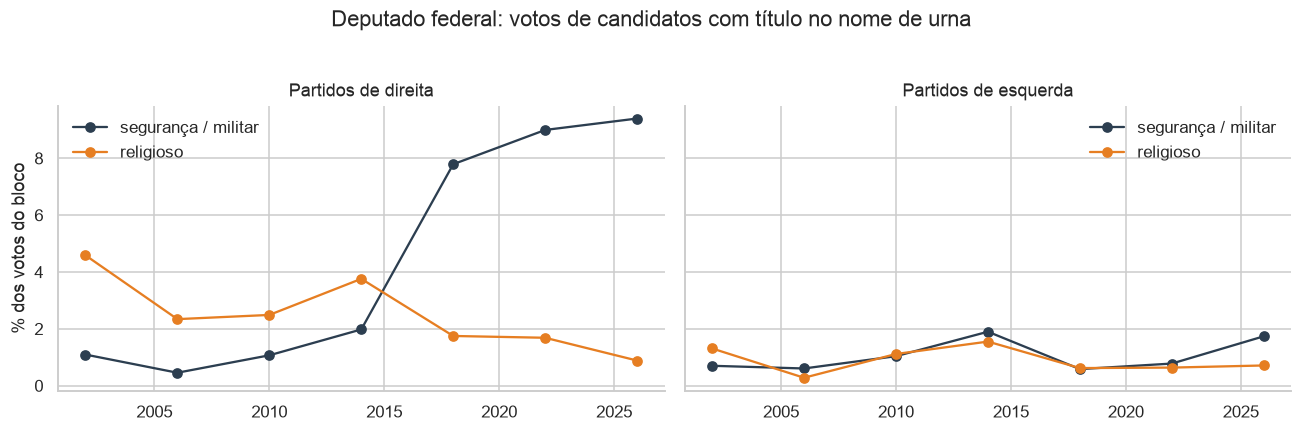

DIREITA — % dos votos do bloco, por título no nome de urna
titulo  religioso  segurança / militar  sem título
ano                                               
2002          4.6                  1.1        94.3
2006          2.3                  0.5        97.2
2010          2.5                  1.1        96.4
2014          3.8                  2.0        94.3
2018          1.7                  7.8        90.5
2022          1.7                  9.0        89.3
2026          0.9                  9.4        89.7

ESQUERDA — idem
titulo  religioso  segurança / militar  sem título
ano                                               
2002          1.3                  0.7        98.0
2006          0.3                  0.6        99.1
2010          1.1                  1.0        97.8
2014          1.6                  1.9        96.6
2018          0.6                  0.6        98.8
2022          0.6                  0.8        98.6
2026          0.7                  1.7        97.6


In [ ]:
import re
vc = pd.read_parquet(P + "votos_candidato_uf.parquet")
x = vc[(vc.cargo == "dep_federal") & (vc.NR_TURNO == 1) & (vc.SG_UF != "ZZ")].merge(ide, on="SG_PARTIDO", how="left")
titulo_seg = re.compile(r"\b(DELEGAD[OA]|CABO|SARGENTO|SGT|SOLDADO|CORONEL|MAJOR|CAPIT[AÃ]O|TENENTE|POLICIAL|COMANDANTE|INSPETOR)\b")
titulo_rel = re.compile(r"\b(PASTOR[A]?|BISPO|BISPA|APOSTOLO|APÓSTOLO|MISSION[AÁ]RI[OA]|PADRE|EVANGELISTA)\b")
nu = x.NM_URNA_CANDIDATO.fillna("").str.upper()
x["titulo"] = np.where(nu.str.contains(titulo_seg), "segurança / militar",
               np.where(nu.str.contains(titulo_rel), "religioso", "sem título"))
print("votos para deputado federal (milhões):"); print((x.groupby("ano").QT_VOTOS_NOMINAIS.sum() / 1e6).round(1).to_string())

def partilha(ideo):
    d = x[x.ideologia == ideo]
    t = d.pivot_table(index="ano", columns="titulo", values="QT_VOTOS_NOMINAIS", aggfunc="sum", fill_value=0)
    return 100 * t.div(t.sum(axis=1), axis=0)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, ideo in zip(axs, ["direita", "esquerda"]):
    partilha(ideo)[["segurança / militar", "religioso"]].plot(ax=ax, marker="o", color=["#2c3e50", "#e67e22"])
    ax.set_title(f"Partidos de {ideo}"); ax.set_ylabel("% dos votos do bloco"); ax.set_xlabel("")
    ax.legend(frameon=False)
fig.suptitle("Deputado federal: votos de candidatos com título no nome de urna", y=1.03)
plt.tight_layout(); plt.show()
print("DIREITA — % dos votos do bloco, por título no nome de urna"); print(partilha("direita").round(1).to_string())
print("\nESQUERDA — idem"); print(partilha("esquerda").round(1).to_string())

## 9. O que esta análise não cobre

- **Eleitor individual.** Todos os perfis são de município. Não sei quem mudou o voto, se foi o mesmo eleitor ou se mudou a composição (migração, abstenção, renovação geracional).
- **Classificação dos partidos.** É um julgamento. PSDB, MDB, PSD e outros ficam no centro; PTB, PP e PL na direita; PSB e PV na esquerda. Mudar isso muda os números, em especial para 2002–2014, quando a "direita" quase não aparece na eleição presidencial.
- **Candidatos, não partidos, no voto presidencial.** Em 2002, por exemplo, Garotinho (PSB) conta como esquerda e Ciro (PPS) como centro.
- **Votos de legenda** nas eleições proporcionais e o 2º turno (que em 2026 ainda não ocorreu).
- **Efeito do candidato.** Parte da queda da esquerda em 2018 é Bolsonaro e parte de 2026 é Flávio ou Lula como pessoas, não o espectro ideológico.
- **Causas.** Os dados mostram onde e com que perfil, não por quê. Segurança pública, economia, rejeição ao PT, igrejas e redes sociais são hipóteses que não testo aqui.
- **Idade do eleitorado:** só tenho 16–24 e 60+ por município (faixas do TSE), não a série completa por idade.
- **Exterior** e voto em trânsito ficam de fora.

## 10. Conclusões

- Sim, há uma virada de esquerda para direita entre municípios e estados que votavam majoritariamente à esquerda até 2014: **39% desses municípios** (1.608) e **16 UFs** têm a direita à frente em 2026.
- Ela se concentra em **Sul, Sudeste, Centro-Oeste e parte do Norte** (em Minas e Tocantins, só em parte dos municípios) e quase toda já aparecia em 2018. 2026 acrescenta 328 municípios e dois estados (TO e AP).
- A virada é muito mais forte no **voto presidencial** do que em deputados e senadores, e nos municípios que viraram a direita lidera todos os cargos em 2026 (75% a 90% dos votos).
- Os municípios que viraram são **mais urbanos, mais ricos, mais evangélicos e menos pretos/pardos**. Dentro do mesmo estado, evangélicos e cor/raça são os fatores mais associados à direita. Para 2022→2026 esse padrão enfraquece.
- Entre os políticos, o crescimento visível na direita é de **candidatos com título de segurança/militar** no nome de urna.
- Tudo isso é correlação entre municípios, sob uma classificação de partidos que é discutível; nada aqui diz como os eleitores individuais votaram.